In [1]:
import pathlib
import sys

from matplotlib import pyplot as plt

# the analysis code lives in r18b05lexa_r60d05gal4_analysis.py next to this notebook
# (run it as a script to regenerate everything: python r18b05lexa_r60d05gal4_analysis.py)
sys.path.insert(0, str(pathlib.Path.cwd()))
import r18b05lexa_r60d05gal4_analysis as ana

plt.rcParams['pdf.fonttype'] = 42

%load_ext autoreload
%autoreload 2
%matplotlib inline

In [2]:
sess_manager = ana.load_session_manager()     # folders: see ana.BASEDIR, ana.DEFAULT_FIGDIR
sess_manager.sess_df.head()

,date,fly,sess,fictrac_scan_num,fictrac_file,condition,scan_type,usable,notes,session,fly_id
0,11_07_2024,fly1,baseline-000,0,fictrac-20240711_112205.dat,remap,baseline,NaN,NaN,baseline-000,11_07_2024_fly1_condition_remap
1,11_07_2024,fly1,remap_0deg-001,1,fictrac-20240711_112205.dat,remap,remap_0deg,NaN,NaN,remap_0deg-001,11_07_2024_fly1_condition_remap
2,11_07_2024,fly1,post_0deg-002,2,fictrac-20240711_112205.dat,remap,post_0deg,NaN,NaN,post_0deg-002,11_07_2024_fly1_condition_remap
3,11_07_2024,fly1,remap_180deg-004,4,fictrac-20240711_112205.dat,remap,remap_180deg,NaN,NaN,remap_180deg-004,11_07_2024_fly1_condition_remap
4,11_07_2024,fly1,post_180deg-006,6,fictrac-20240711_112205.dat,remap,post_180deg,NaN,NaN,post_180deg-006,11_07_2024_fly1_condition_remap


## Optogenetic responses

opto_window_tests


,comparison,U,p,p_holm
0,EL stim vs no CsChrimson,134.0,0.000201,0.000401
1,EL stim vs no visual cue,59.0,0.487960,0.487960


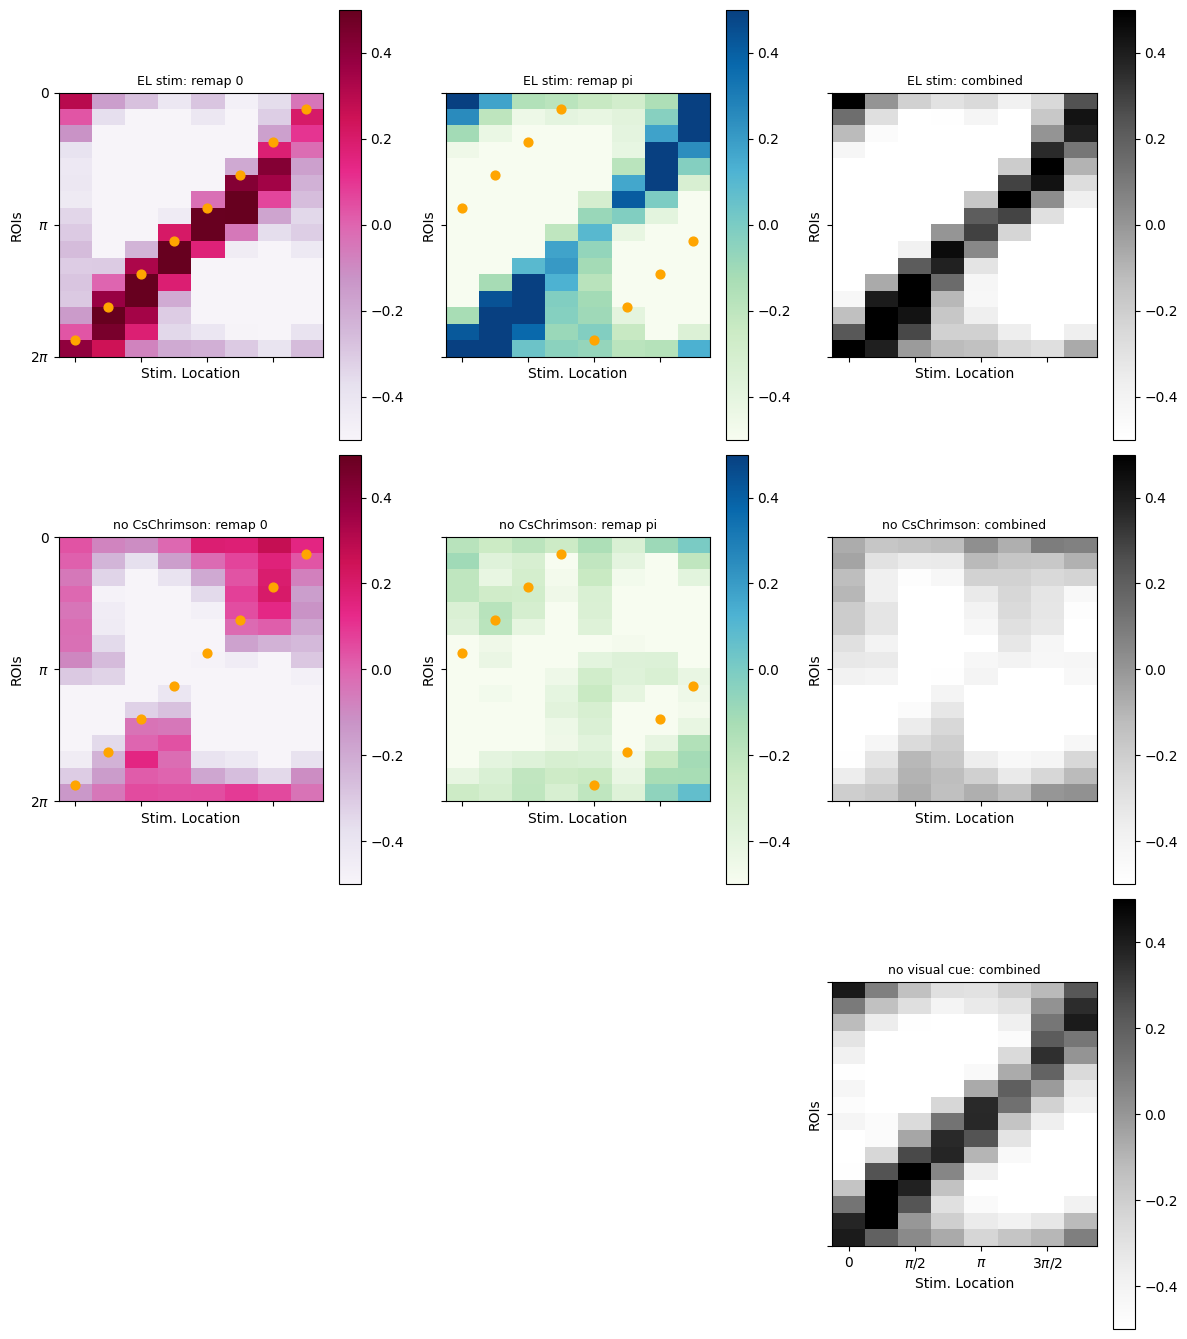

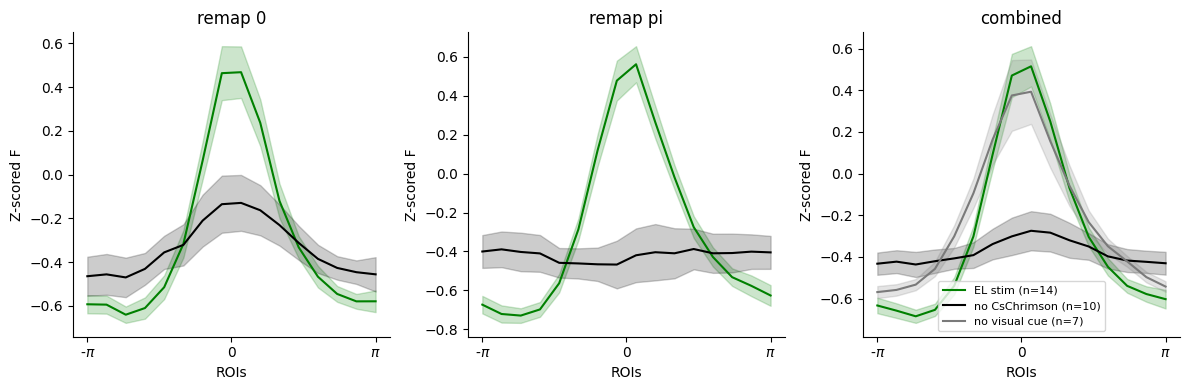

In [3]:
aligned_opto, opto_tables = ana.opto_analysis(sess_manager)
for name, table in opto_tables.items():
    print(name)
    display(table) if hasattr(table, 'columns') else print(table)

## Offset remapping

remap remap 0 -0.03166768379248059
remap remap 180 3.1200250199780886
no_chrimson remap 0 0.37106377823911274
no_chrimson remap 180 -0.21297812457618695
remapping_error_tests


,family,comparison,n,W,p,p_holm
0,error vs chance,EL stim,14.0,0.0,0.000122,0.000366
1,error vs chance,no CsChrimson,9.0,20.0,0.820312,1.000000
2,error vs chance,no visual cue,10.0,24.0,0.769531,1.000000
3,error between groups,EL stim vs no CsChrimson,NaN,0.0,0.000082,0.000094
4,error between groups,EL stim vs no visual cue,NaN,0.0,0.000047,0.000094


mean_offsets


,group,scan_type,n_flies,mean_offset,mean_vec_len
0,remap,baseline,14,0.277998,0.183315
1,remap,post_0deg,14,-0.031668,0.449792
2,remap,post_180deg,14,3.120025,0.416212
3,no_chrimson,baseline,10,-0.013164,0.273383
4,no_chrimson,post_0deg,10,0.371064,0.286318
5,no_chrimson,post_180deg,9,-0.212978,0.233346
6,novis_control,baseline,10,-0.869826,0.050918
7,novis_control,post_novis1,10,-0.960694,0.225536
8,novis_control,post_novis2,10,-0.555283,0.159105


n_flies


,group,n_flies
0,remap,14
1,no_chrimson,10
2,novis_control,10


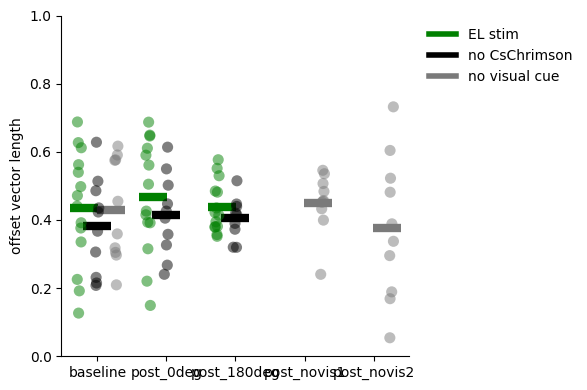

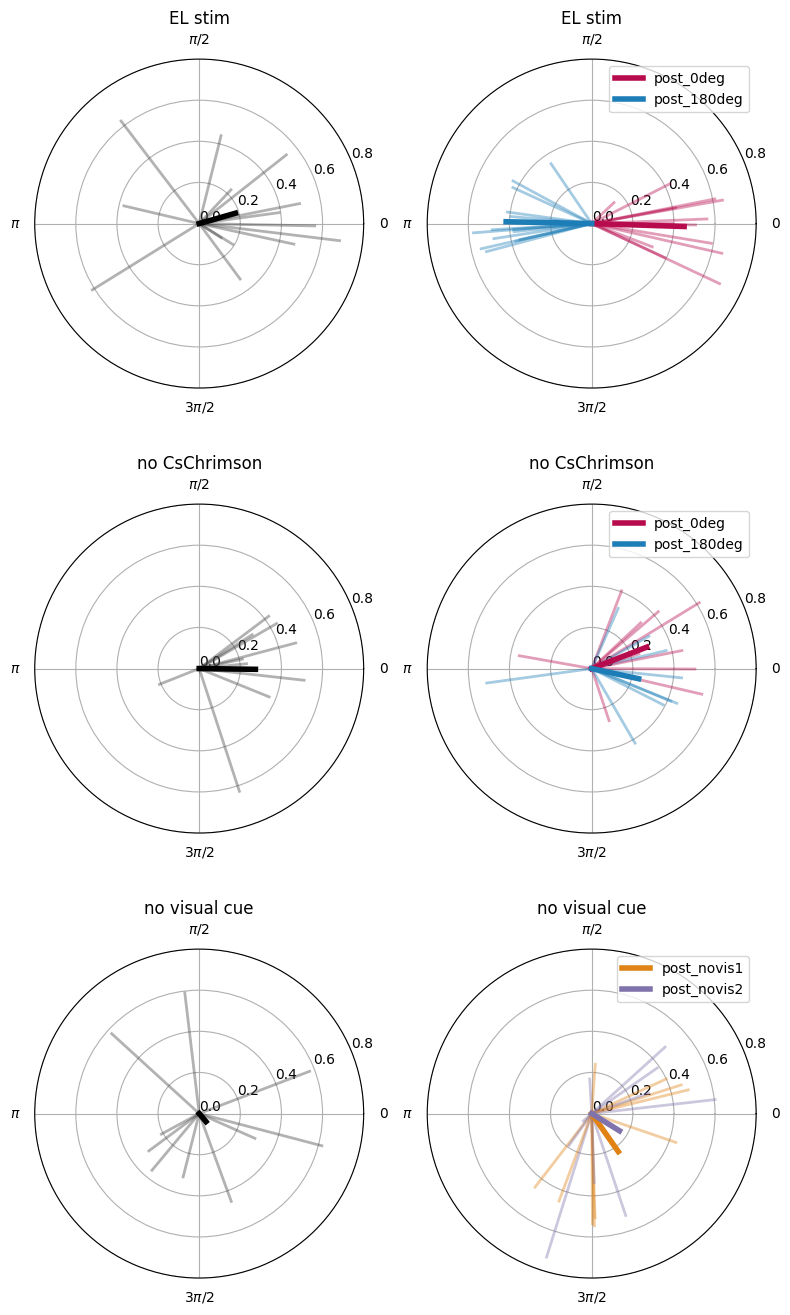

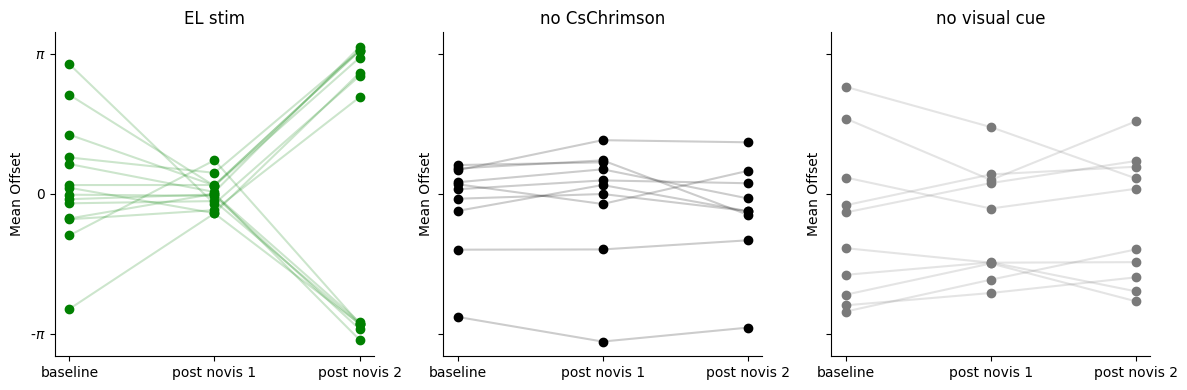

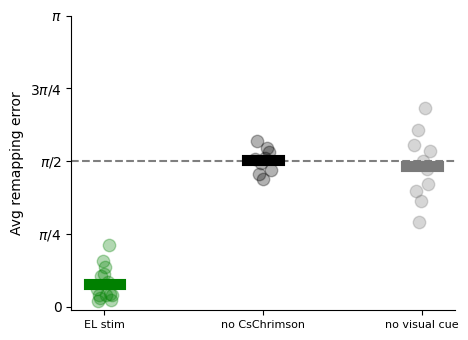

In [4]:
offset_summary, offset_tables = ana.offset_analysis(sess_manager)
for name, table in offset_tables.items():
    print(name)
    display(table) if hasattr(table, 'columns') else print(table)

## Heatmaps and offset histograms of every fly

In [5]:
plotted_flies = ana.plot_session_figures(sess_manager)
len(plotted_flies)

23